In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Upload the Excel workbook**

In [2]:
import os

file_path = r"C:\Users\shubhAM\Desktop\RetailPulse_ZIDIO_INTERNSHIP\online_retail_II.xlsx"

print("Resolved file_path:", file_path)
print("File exists:", os.path.exists(file_path))


Resolved file_path: C:\Users\shubhAM\Desktop\RetailPulse_ZIDIO_INTERNSHIP\online_retail_II.xlsx
File exists: True


In [3]:
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

df_2009 = pd.read_excel(file_path, sheet_name='Year 2009-2010')
df_2010 = pd.read_excel(file_path, sheet_name='Year 2010-2011')
df = pd.concat([df_2009, df_2010], ignore_index=True)

['Year 2009-2010', 'Year 2010-2011']


In [4]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print()
print(df.info())

Shape: (1067371, 9)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
 8   Revenue      1067371 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 73.3+ MB
None


In [5]:
print("MISSING VALUES")
print(df.isnull().sum())

print("\nMISSING VALUE PERCENTAGE")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

# 3. Count completely duplicated rows
print("\nDUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())

# 4. Inspect numerical columns
print("\nNUMERICAL SUMMARY")
print(df[["Quantity", "Price"]].describe())

print("\ncolumn name")
print(df.columns.tolist)



MISSING VALUES
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
Revenue             0
dtype: int64

MISSING VALUE PERCENTAGE
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
Revenue         0.00
dtype: float64

DUPLICATE ROWS
Duplicate rows: 34335

NUMERICAL SUMMARY
           Quantity         Price
count  1.067371e+06  1.067371e+06
mean   9.938898e+00  4.649388e+00
std    1.727058e+02  1.235531e+02
min   -8.099500e+04 -5.359436e+04
25%    1.000000e+00  1.250000e+00
50%    3.000000e+00  2.100000e+00
75%    1.000000e+01  4.150000e+00
max    8.099500e+04  3.897000e+04

column name
<bound method IndexOpsMixin.tolist of Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Revenue'],
   

In [6]:

# 1. Check the date range
print("DATE RANGE")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

# 2. Inspect quantity values
print("\nQUANTITY CHECK")
print("Negative:", (df["Quantity"] < 0).sum())
print("Zero:", (df["Quantity"] == 0).sum())
print("Positive:", (df["Quantity"] > 0).sum())

# 3. Inspect price values
print("\nPRICE CHECK")
print("Negative:", (df["Price"] < 0).sum())
print("Zero:", (df["Price"] == 0).sum())
print("Positive:", (df["Price"] > 0).sum())

# 4. Check invoice identifiers beginning with C
invoice_text = df["Invoice"].astype(str).str.strip()
cancelled_prefix = invoice_text.str.upper().str.startswith("C")

print("\nINVOICE PREFIX CHECK")
print("Invoices beginning with C:", cancelled_prefix.sum())
print("Negative quantities with C prefix:",
      (cancelled_prefix & (df["Quantity"] < 0)).sum())
print("Negative quantities without C prefix:",
      ((~cancelled_prefix) & (df["Quantity"] < 0)).sum())

# 5. Inspect unusual transactions
print("\nNEGATIVE QUANTITY EXAMPLES")
display(df.loc[df["Quantity"] < 0,
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue"]].head(10))

print("\nNEGATIVE PRICE EXAMPLES")
display(df.loc[df["Price"] < 0,
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue"]].head(10))

# 6. Inspect duplicate examples
print("\nDUPLICATE EXAMPLES")
display(df.loc[df.duplicated(keep=False)].head(10))


DATE RANGE
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00

QUANTITY CHECK
Negative: 22950
Zero: 0
Positive: 1044421

PRICE CHECK
Negative: 5
Zero: 6202
Positive: 1061164

INVOICE PREFIX CHECK
Invoices beginning with C: 19494
Negative quantities with C prefix: 19493
Negative quantities without C prefix: 3457

NEGATIVE QUANTITY EXAMPLES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,-17.00
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,-12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,-35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,-15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,-15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,-20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,-35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,-12.75



NEGATIVE PRICE EXAMPLES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,-38925.87
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,-11062.06
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,-11062.06



DUPLICATE EXAMPLES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75


Visual EDA

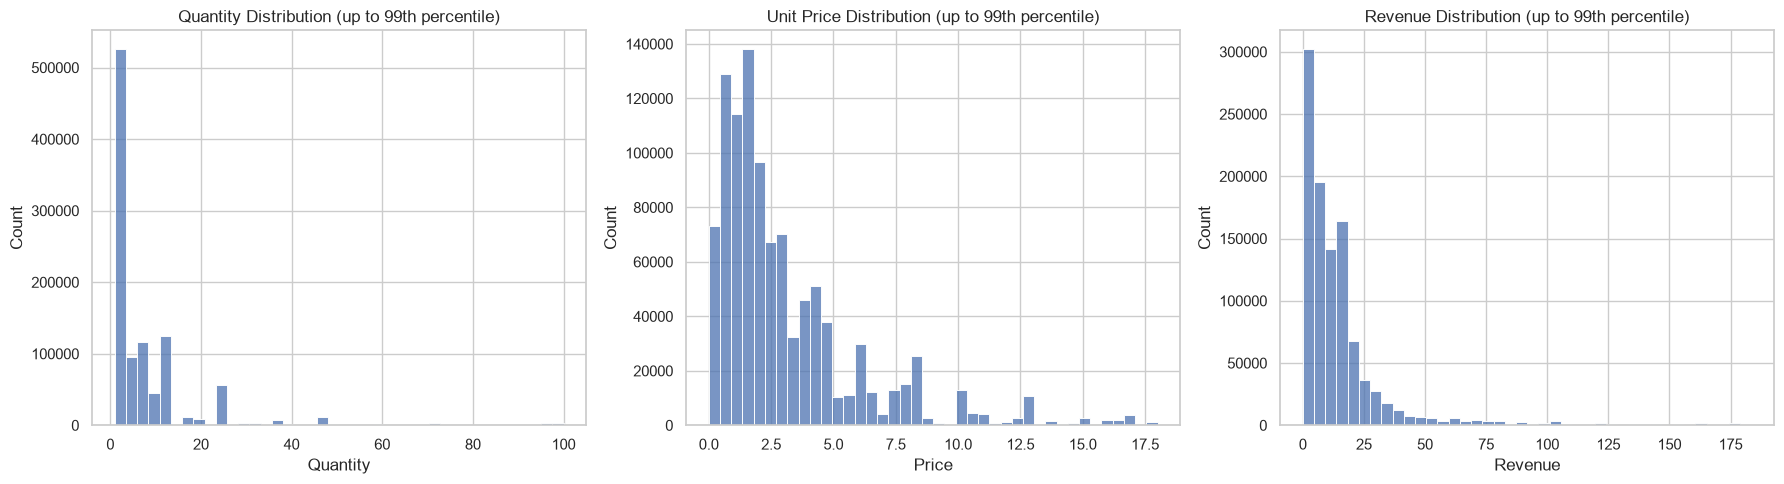

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Use ordinary product-line records for these initial plots.
# This is a temporary plotting subset, not a cleaned dataset.
sales_view = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

# Limit the displayed range to the 99th percentile
# so extreme values don't compress the main distributions.
quantity_limit = sales_view["Quantity"].quantile(0.99)
price_limit = sales_view["Price"].quantile(0.99)
revenue_limit = sales_view["Revenue"].quantile(0.99)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    sales_view.loc[
        sales_view["Quantity"] <= quantity_limit, "Quantity"
    ],
    bins=40, ax=axes[0]
)
axes[0].set_title("Quantity Distribution (up to 99th percentile)")
axes[0].set_xlabel("Quantity")

sns.histplot(
    sales_view.loc[
        sales_view["Price"] <= price_limit, "Price"
    ],
    bins=40, ax=axes[1]
)
axes[1].set_title("Unit Price Distribution (up to 99th percentile)")
axes[1].set_xlabel("Price")

sns.histplot(
    sales_view.loc[
        sales_view["Revenue"] <= revenue_limit, "Revenue"
    ],
    bins=40, ax=axes[2]
)
axes[2].set_title("Revenue Distribution (up to 99th percentile)")
axes[2].set_xlabel("Revenue")

plt.tight_layout()
plt.show()


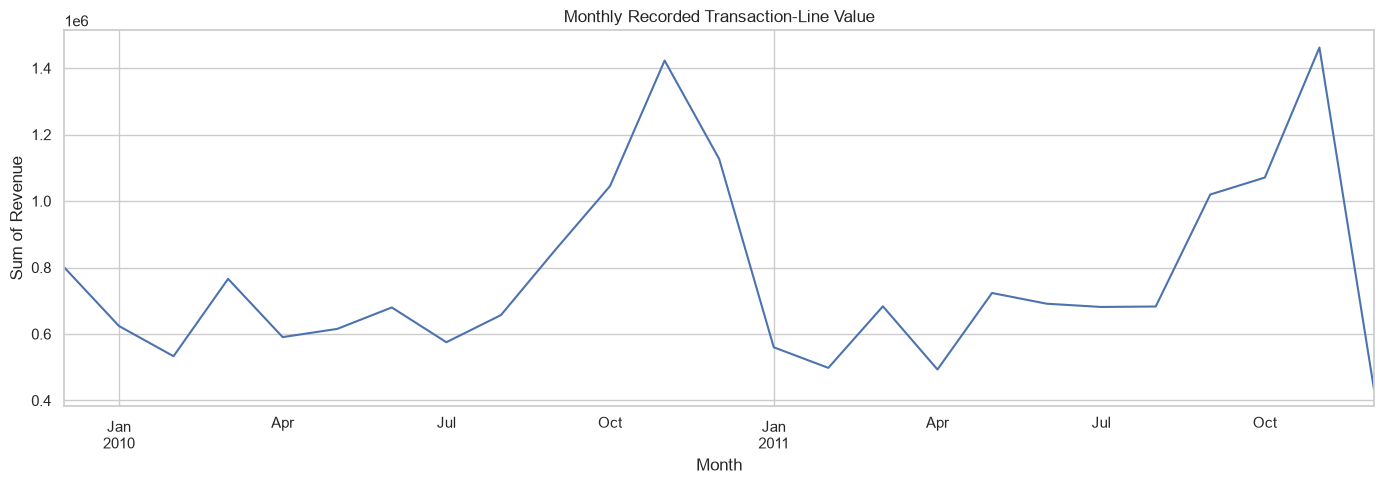

In [8]:

# Group transactions by calendar month and sum their line values
monthly_revenue = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(14, 5))
monthly_revenue.plot()

plt.title("Monthly Recorded Transaction-Line Value")
plt.xlabel("Month")
plt.ylabel("Sum of Revenue")
plt.tight_layout()
plt.show()


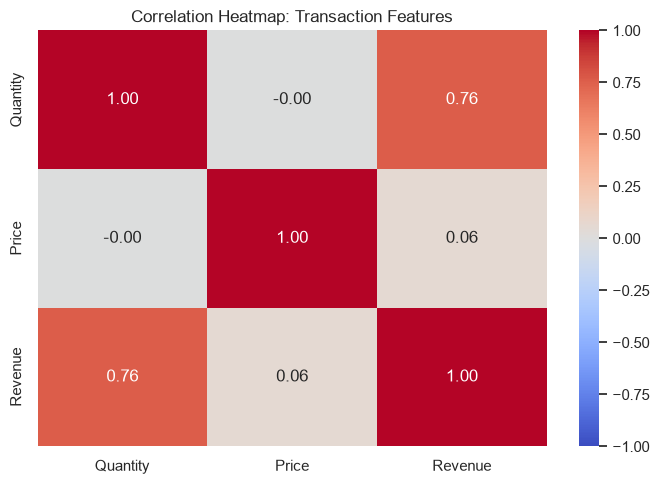

In [9]:

numeric_features = df[["Quantity", "Price", "Revenue"]]

correlation_matrix = numeric_features.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap: Transaction Features")
plt.tight_layout()
plt.show()


In [10]:

# Monthly total recorded transaction-line value
monthly_summary = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("MS")
      .sum()
)

# Display October 2010 through January 2011
period = monthly_summary.loc["2010-10":"2011-01"]

print("Monthly recorded revenue:")
display(period.to_frame(name="Revenue").round(2))

# Calculate percentage change from one month to the next
print("\nMonth-over-month percentage change:")
display(period.pct_change().mul(100).to_frame(
    name="Change (%)"
).round(2))


Monthly recorded revenue:


,Revenue
InvoiceDate,
2010-10-01,1045168.35
2010-11-01,1422654.64
2010-12-01,1126445.47
2011-01-01,560000.26



Month-over-month percentage change:


,Change (%)
InvoiceDate,
2010-10-01,NaN
2010-11-01,36.12
2010-12-01,-20.82
2011-01-01,-50.29


In [11]:

product_summary = (
    sales_view.groupby("StockCode")
    .agg(
        Units_Sold=("Quantity", "sum"),
        Recorded_Revenue=("Revenue", "sum"),
        Description=("Description", "first")
    )
    .sort_values("Recorded_Revenue", ascending=False)
)

print("Top 10 products by recorded revenue:")
display(product_summary.head(10))


Top 10 products by recorded revenue:


,Units_Sold,Recorded_Revenue,Description
StockCode,,,
22423,27577,344563.25,REGENCY CAKESTAND 3 TIER
M,10051,341089.85,Manual
DOT,1436,322657.48,DOTCOM POSTAGE
85123A,96147,263109.67,WHITE HANGING HEART T-LIGHT HOLDER
85099B,98349,183454.83,JUMBO BAG RED WHITE SPOTTY
23843,80995,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
47566,28378,149187.05,PARTY BUNTING
84879,81809,132187.92,ASSORTED COLOUR BIRD ORNAMENT
POST,5461,127597.42,POSTAGE
